In [ ]:
import pandas as pd

# Membaca dataset dengan pemisah titik koma (;)
df = pd.read_csv('weather_dataset.csv', sep=';')

# Menampilkan 5 baris pertama data
print("--- 5 Baris Pertama ---")
display(df.head())

# Menampilkan daftar nama kolom yang benar
print("\n--- Nama-Nama Kolom di Dataset ---")
print(df.columns.tolist())

--- 5 Baris Pertama ---


,Pressure,global_radiation,temp_mean(c),temp_min(c),temp_max(c),Wind_Speed,Wind_Bearing,normalized_label
0,971.5,0.25,9.0,7.0,10.7,0.0,0.0,0.0
1,972.3,0.97,10.5,6.7,13.5,0.0,0.0,0.0
2,972.4,0.74,6.5,3.9,9.1,0.0,0.0,0.0
3,973.2,0.15,5.1,3.7,7.7,0.0,0.0,0.0
4,975.7,0.12,5.2,2.6,8.3,0.0,0.0,0.0



--- Nama-Nama Kolom di Dataset ---
['Pressure', 'global_radiation', 'temp_mean(c)', 'temp_min(c)', 'temp_max(c)', 'Wind_Speed', 'Wind_Bearing', 'normalized_label']


In [ ]:
df.describe()

,Pressure,global_radiation,temp_mean(c),temp_min(c),temp_max(c),Wind_Speed,Wind_Bearing,normalized_label
count,253616.000000,253616.000000,253616.000000,253616.000000,253616.000000,253615.000000,253615.000000,253615.000000
mean,1008.889232,1.144917,11.762536,8.067618,15.737767,12.855659,195.031942,0.931609
std,2.988525,0.814164,6.356628,5.878953,7.386196,7.997605,97.405187,1.024541
min,971.500000,0.030000,-11.100000,-16.000000,-8.500000,0.000000,0.000000,0.000000
25%,1007.600000,0.430000,7.100000,3.700000,10.400000,6.620000,140.000000,0.000000
50%,1009.700000,0.960000,12.200000,8.400000,15.800000,11.270000,190.000000,1.000000
75%,1011.100000,1.740000,16.600000,12.800000,21.000000,16.970000,280.000000,2.000000
max,1012.100000,3.570000,27.900000,21.500000,36.200000,47.090000,359.000000,3.000000


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
# 1. Load dataset
df = pd.read_csv('weather_dataset.csv', sep=';')

# Menentukan Target (Y) dan 1 Variabel Bebas (X)
target = 'temp_mean(c)'
feature_simple = ['global_radiation']

df_s = df.dropna(subset=[target] + feature_simple)

X_s = df_s[feature_simple]
y_s = df_s[target]

# Splitting Data
X_s_train, X_s_test, y_s_train, y_s_test = train_test_split(X_s, y_s, test_size=0.2, random_state=42)

In [ ]:
# Fitting Model Sederhana
model_simple = LinearRegression()
model_simple.fit(X_s_train, y_s_train)

#Melihat Intercept dan Koefisien
print("Koefisien:", model_simple.coef_)
print("Intercept:", model_simple.intercept_)


Koefisien: [4.98839178]
Intercept: 6.1062922718447705


In [ ]:
# Prediksi & Evaluasi
y_pred_s = model_simple.predict(X_s_test)
mae_s = mean_absolute_error(y_s_test, y_pred_s)
rmse_s = np.sqrt(mean_squared_error(y_s_test, y_pred_s))
r2_s = r2_score(y_s_test, y_pred_s)

print("="*40)
print("MODEL: REGRESI LINEAR SEDERHANA")
print("="*40)
print(f"Persamaan: Y = {model_simple.intercept_:.4f} + {model_simple.coef_[0]:.4f} * X")
print(f"MAE  : {mae_s:.4f}")
print(f"RMSE : {rmse_s:.4f}")
print(f"R2   : {r2_s:.4f}")


MODEL: REGRESI LINEAR SEDERHANA
Persamaan: Y = 6.1063 + 4.9884 * X
MAE  : 3.8175
RMSE : 4.7304
R2   : 0.4726


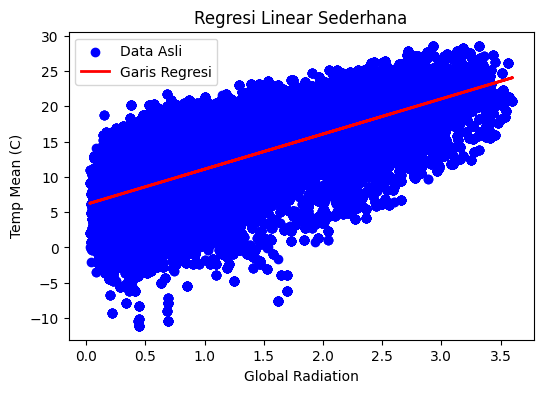

In [ ]:
# Visualisasi Scatter Plot & Garis Regresi Sederhana
plt.figure(figsize=(6, 4))
plt.scatter(X_s_test, y_s_test, color='blue', label='Data Asli')
plt.plot(X_s_test, y_pred_s, color='red', linewidth=2, label='Garis Regresi')
plt.title('Regresi Linear Sederhana')
plt.xlabel('Global Radiation')
plt.ylabel('Temp Mean (C)')
plt.legend()
plt.show()

In [ ]:
import statsmodels.api as sm
from sklearn.model_selection import train_test_split

# Tentukan Target (Y) dan Lebih dari 1 Variabel Bebas (X)
target = 'temp_mean(c)'
features_multi = ['global_radiation', 'Pressure']

df_m = df.dropna(subset=[target] + features_multi)

X_m = df_m[features_multi]
y_m = df_m[target]

# Splitting Data
X_m_train, X_m_test, y_m_train, y_m_test = train_test_split(X_m, y_m, test_size=0.2, random_state=42)

In [ ]:
from sklearn.linear_model import LinearRegression

# Fitting Model Linear Berganda
model_multi = LinearRegression()
model_multi.fit(X_m_train, y_m_train)

# Menampilkan nilai koefisien & nilai intercept setiap variabel
print("Koefisien:", model_multi.coef_)
print("Intercept:", model_multi.intercept_)

Koefisien: [4.97690878 0.13450328]
Intercept: -129.63346179607774


In [ ]:
# Prediksi & Evaluasi
y_pred_m = model_multi.predict(X_m_test)
mae_m = mean_absolute_error(y_m_test, y_pred_m)
rmse_m = np.sqrt(mean_squared_error(y_m_test, y_pred_m))
r2_m = r2_score(y_m_test, y_pred_m)

print("="*40)
print("MODEL: REGRESI LINEAR BERGANDA")
print("="*40)
print(f"MAE  : {mae_m:.4f}")
print(f"RMSE : {rmse_m:.4f}")
print(f"R2   : {r2_m:.4f}")

MODEL: REGRESI LINEAR BERGANDA
Persamaan: Y = -129.6335 + 4.9769 * X1 + 0.1345 * X2
MAE  : 3.8926
RMSE : 4.8228
R2   : 0.4260


Text(0, 0.5, 'Residuals')

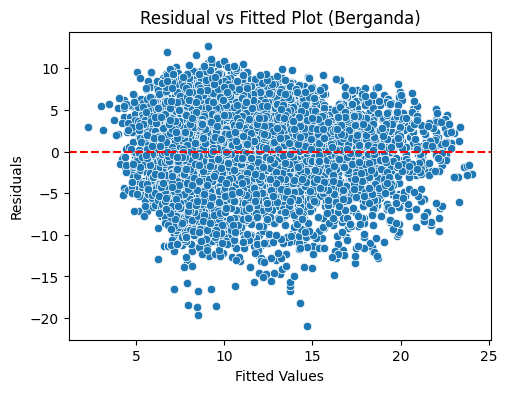

In [ ]:
# Visualisasi Diagnostik untuk Regresi Berganda (Residual & Q-Q Plot)
X_m_sm = sm.add_constant(X_m_test)
model_sm = sm.OLS(y_m_test, X_m_sm).fit()
residuals = model_sm.resid
fitted = model_sm.fittedvalues

plt.figure(figsize=(12, 4))

# Residual vs Fitted
plt.subplot(1, 2, 1)
sns.scatterplot(x=fitted, y=residuals)
plt.axhline(0, color='red', linestyle='--')
plt.title('Residual vs Fitted Plot (Berganda)')
plt.xlabel('Fitted Values')
plt.ylabel('Residuals')

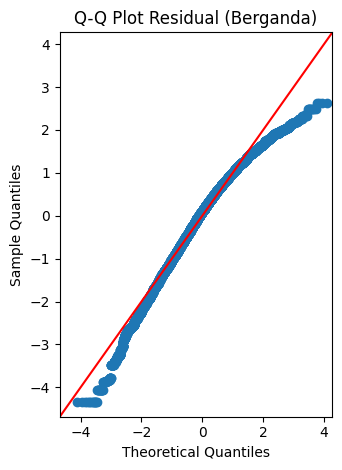

In [ ]:
# Q-Q Plot
plt.subplot(1, 2, 2)
sm.qqplot(residuals, line='45', fit=True, ax=plt.subplot(1, 2, 2))
plt.title('Q-Q Plot Residual (Berganda)')

plt.tight_layout()
plt.show()

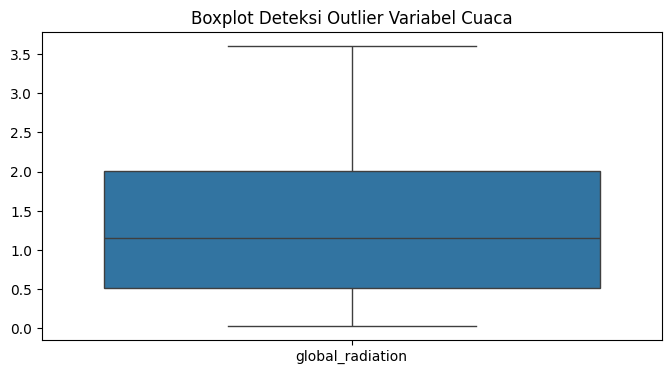

In [25]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 4))
sns.boxplot(data=df[['global_radiation']])
plt.title("Boxplot Deteksi Outlier Variabel Cuaca")
plt.show()

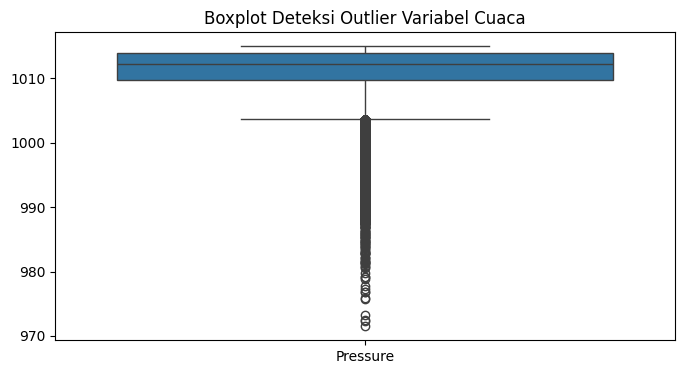

In [26]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 4))
sns.boxplot(data=df[['Pressure']])
plt.title("Boxplot Deteksi Outlier Variabel Cuaca")
plt.show()

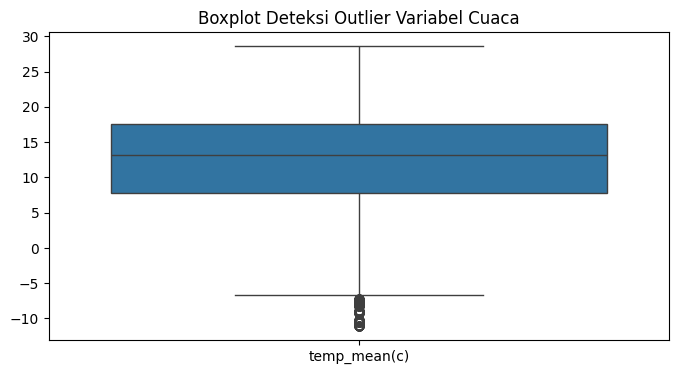

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 4))
sns.boxplot(data=df[['temp_mean(c)']])
plt.title("Boxplot Deteksi Outlier Variabel Cuaca")
plt.show()